# 02-regression

In [4]:
import pandas as pd
import numpy as np

In [145]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [146]:
cols_to_use = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']
df = df[cols_to_use]
df.keys()

Index(['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year',
       'fuel_efficiency_mpg'],
      dtype='str')

## EDA

In [147]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

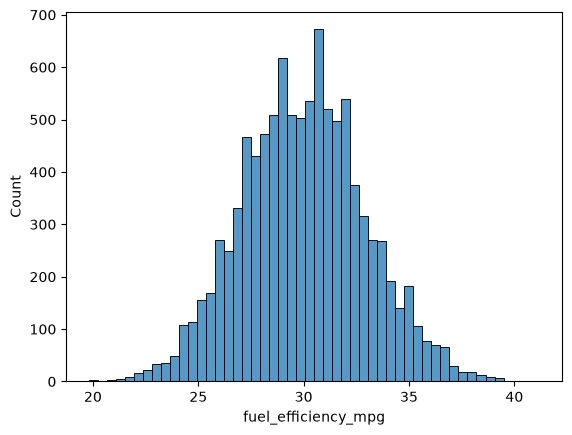

In [148]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

> Look at the fuel_efficiency_mpg variable. Does it have a long tail?

No, it doesn't have a long tail.

In [149]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

engine_displacement
[2180 2390 2320 2130 2580]
127

horsepower
[243. 272. 267. 258. 304.]
153

vehicle_weight
[3870 4210 4240 4490 4510]
176

model_year
[2006 2008 1996 1989 1994]
50

fuel_efficiency_mpg
[31.9 31.3 27.5 28.5 31. ]
188



## Question 1

In [150]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

horsepower has missing values.

## Question 2

In [151]:
horsepower_median = df['horsepower'].median()

In [152]:
print(f"Median Horsepower: {horsepower_median}")

Median Horsepower: 254.0


## Prepare and Split dataset

In [101]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [102]:
### Prepare X to replace car model with age? maybe no...

### Function for training model with linear regression

In [103]:
def train_linear_regression_reg(X, y, r=0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [104]:
def prepare_X(df):
    X = df.values

    return X

In [105]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

## Question 3

### Dealing with missing values
#### Option 1: Replace with zero

In [106]:
df_with_zero = df_train.fillna(0)
X_train_zero = df_with_zero.values
w0, w = train_linear_regression_reg(X_train_zero, y_train)
w0, w

(np.float64(-2.548879880787878),
 array([-4.93996322e-05,  3.99285304e-06, -1.29300047e-04,  3.32220821e-03]))

#### Evaluate using validation data and RMSE

In [107]:
X_val = df_val.fillna(0).values
y_pred = w0 + X_val.dot(w)

In [108]:
round(rmse(y_val, y_pred), 3)

np.float64(0.071)

#### Option 2: Replace with mean

In [109]:
mean_horsepower = df['horsepower'].mean()
print(f"Mean Horsepower: {mean_horsepower}")

Mean Horsepower: 254.44601556505535


In [110]:
df_with_mean = df_train.fillna(mean_horsepower)
X_train_mean = df_with_mean.values
w0, w = train_linear_regression_reg(X_train_mean, y_train)
w0, w

(np.float64(-2.5458454588229125),
 array([-3.44295192e-05, -1.93776986e-04, -1.27256856e-04,  3.32445490e-03]))

#### Evaluate using validation data and RMSE

In [111]:
X_val = df_val.fillna(mean_horsepower).values
y_pred = w0 + X_val.dot(w)

In [112]:
round(rmse(y_val, y_pred), 3)

np.float64(0.071)

## Question 4

In [114]:
df_with_zero = df_train.fillna(0)
X_train_zero = df_with_zero.values
w0, w = train_linear_regression_reg(X_train_zero, y_train)
w0, w

(np.float64(-2.548879880787878),
 array([-4.93996322e-05,  3.99285304e-06, -1.29300047e-04,  3.32220821e-03]))

In [116]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    df_with_zero = df_train.fillna(0)
    X_train_zero = df_with_zero.values
    w0, w = train_linear_regression_reg(X_train_zero, y_train, r=r)

    X_val = df_val.fillna(0).values
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    
    print(r, w0, round(score, 4))

0 -2.548879880787878 0.0715
0.01 -2.456525696928604 0.0715
0.1 -1.8524448492907521 0.0717
1 -0.535529553803343 0.0727
5 -0.1287451934306354 0.0733
10 -0.06603998348984993 0.0734
100 -0.006760761337059787 0.0735


## Question 5

In [153]:
scores = []
for s in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
    df_test = df.iloc[idx[n_train + n_val:]].copy()
    
    y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
    y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
    y_test = np.log1p(df_test.fuel_efficiency_mpg.values)
    
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    # train model
    df_with_zero = df_train.fillna(0)
    X_train_zero = df_with_zero.values
    w0, w = train_linear_regression_reg(X_train_zero, y_train, r=0)

    # test with validation dataset
    X_val = df_val.fillna(0).values
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    scores.append(score)

result = np.std(scores)
round(result, 3)


np.float64(0.001)

## Question 6

In [160]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

df_test_original = df_test.copy()

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [139]:
df_full_train = pd.concat([df_train, df_val])

In [140]:
df_full_train = df_full_train.reset_index(drop=True)

In [141]:
X_full_train = df_full_train.fillna(0).values

In [142]:
y_full_train = np.concatenate([y_train, y_val])

In [143]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

In [167]:
X_test = df_test.fillna(0).values
y_pred = w0 + X_test.dot(w)

y_pred_mpg = np.expm1(y_pred)
score = rmse(y_test, y_pred)

# compute RMSE on the original MPG values
rmse_orig = np.sqrt(np.mean((y_test - y_pred_mpg) ** 2))
round(rmse_orig, 3)

np.float64(26.603)

In [169]:
rmse(y_test, y_pred_mpg)

np.float64(26.60284511433774)

In [172]:
y_test_orig = df_test_original['fuel_efficiency_mpg'].values
y_pred_mpg = np.expm1(y_pred)

rmse_orig = rmse(y_test_orig, y_pred_mpg)

In [173]:
rmse_orig

np.float64(2.2413333143449403)